In [67]:
import anndata as ad
import scanpy as sc


adata = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/cosmx_nsclc_Lung5-Rep1_adata_annotated.h5ad')
adata = adata[adata.obs['cell_type']!='nan']
# adata = adata[adata.obs['tissue']=='tumor']
# adata = adata[adata.obs['harmony_spatial_tissue']=='Lung5_Rep1']
# adata[adata.obs['split']=='val'].obs

In [69]:
adata.X.max()

array(365)

In [70]:
import numpy as np
top_genes = adata.X.max(axis=0).argsort()[::-1][:20]
[print(x) for x in list(adata.var_names[top_genes])]

adata.X.max()

ENSG00000211895
ENSG00000211896
ENSG00000211592
ENSG00000102837
ENSG00000138166
ENSG00000173272
ENSG00000132465
ENSG00000197956
ENSG00000197746
ENSG00000211893
ENSG00000211899
ENSG00000137673
ENSG00000251562
ENSG00000171345
ENSG00000108821
ENSG00000197253
ENSG00000115414
ENSG00000163735
ENSG00000168542
ENSG00000090382


array(365)

In [22]:
adata.var_names

Index(['C9orf16', 'DDX58', 'ENSG00000000938', 'ENSG00000003402',
       'ENSG00000004468', 'ENSG00000005381', 'ENSG00000005844',
       'ENSG00000005884', 'ENSG00000005893', 'ENSG00000006210',
       ...
       'ENSG00000275302', 'ENSG00000275385', 'ENSG00000275395',
       'ENSG00000275718', 'ENSG00000275896', 'ENSG00000276070',
       'ENSG00000276085', 'ENSG00000277632', 'ENSG00000291237', 'MTRNR2L1'],
      dtype='object', name='index', length=957)

In [ ]:
# adata.obs['harmony_spatial_tissue'].unique()

['Lung12', 'Lung13', 'Lung5_Rep1', 'Lung5_Rep2', 'Lung5_Rep3', 'Lung6', 'Lung9_Rep1', 'Lung9_Rep2']
Categories (8, object): ['Lung5_Rep1', 'Lung5_Rep2', 'Lung5_Rep3', 'Lung6', 'Lung9_Rep1', 'Lung9_Rep2', 'Lung12', 'Lung13']

In [ ]:
# adata_small = sc.pp.subsample(adata, fraction=0.1, random_state=42, copy=True)

,sampled_st_x,sampled_st_y
count,322891.000000,322891.000000
mean,5318.923501,20745.469608
std,16734.084159,125909.353195
min,-38105.666667,-184918.777778
25%,-4040.777778,-28868.777778
50%,8880.444444,7924.777778
75%,16917.722222,155229.666667
max,34701.888889,181061.222222


In [ ]:
# adata_small.write_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated_10pct.h5ad')

In [2]:
adata.obs["Patient"].value_counts()

Patient
p3    82232
p1    66320
p7    48776
p6    45376
p4    39648
p5    36608
p2     3936
Name: count, dtype: int64

In [3]:
import numpy as np
import random
adata_list = []
for tissue in adata.obs['harmony_spatial_tissue'].unique():
    adata_tissue = adata[adata.obs['harmony_spatial_tissue']==tissue].copy()
    x_min,y_min = adata_tissue.obs[['sampled_st_x','sampled_st_y']].min().values
    x_max,y_max = adata_tissue.obs[['sampled_st_x','sampled_st_y']].max().values

    x_size = (x_max-x_min)/10.0
    y_size = (y_max-y_min)/10.0

    x = x_min + 8*x_size
    y = y_min + 2*y_size

    x_v = x_min + 5*x_size
    y_v = y_min + 5*y_size

    train_box = ((adata_tissue.obs['sampled_st_x'] > x)&
                        (adata_tissue.obs['sampled_st_x'] < x+x_size)&
                        (adata_tissue.obs['sampled_st_y'] > y)&
                        (adata_tissue.obs['sampled_st_y'] < y+y_size)&
                (adata_tissue.obs['Patient']!='p5'))

    val_box = ((adata_tissue.obs['sampled_st_x'] > x_v)&
                (adata_tissue.obs['sampled_st_x'] < x_v+x_size)&
                (adata_tissue.obs['sampled_st_y'] > y_v)&
                (adata_tissue.obs['sampled_st_y'] < y_v+y_size)&
                (adata_tissue.obs['Patient']=='p5'))

    adata_small = adata_tissue[train_box | val_box].copy()

    adata_small.obs.loc[:,'split'] = 'train'

    adata_small.obs.loc[((adata_small.obs['sampled_st_x'] > x_v)&
                (adata_small.obs['sampled_st_x'] < x_v+x_size)&
                (adata_small.obs['sampled_st_y'] > y_v)&
                (adata_small.obs['sampled_st_y'] < y_v+y_size)),'split'] = 'val'
    adata_list.append(adata_small)
adata_small= ad.concat(adata_list,join='outer')

In [4]:
adata_small.obs['split'].value_counts()

split
train    3055
val       290
Name: count, dtype: int64

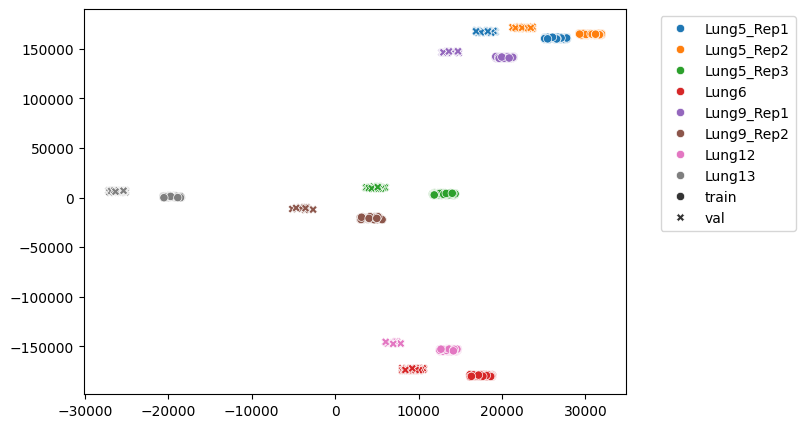

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
fig,ax = plt.subplots(figsize=(7,5))
sns.scatterplot(x=adata_small.obs['sampled_st_x'].values,y=adata_small.obs['sampled_st_y'].values,style=adata_small.obs['split'].values,hue=adata_small.obs['harmony_spatial_tissue'],ax=ax)
ax.legend(bbox_to_anchor=(1.05,1))

In [6]:
print((x_min,x_max),(y_min,y_max))
(x,x+x_size),(y,y+y_size)



(-18939.0, 8401.88888888889) (-28868.7777777778, 3960.22222222222)


((2933.7111111111117, 5667.800000000001),
 (-22302.977777777793, -19020.07777777779))

In [10]:
sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_train_med_with_admix_probs.h5ad')

KeyboardInterrupt: 

In [12]:
adata_small.uns['cell_type_dict'] = adata.uns['cell_type_dict']

In [13]:
adata_small.obs
adata_small.write_h5ad('/compute/oven-0-13/jwinchel/scRNA-seq/adata/GSE127465_tumor_integrated_hardcap_100th.h5ad')